# PART I : Questions 1 - 3

## Imports

In [18]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import matplotlib.cm as cm
import random
from scipy.stats import norm
import pandas as pd

## Data Generation functions

In [19]:
def g(x) :
    """
        True underlying function g(x) = sin²(2πx)

        Arguments:
            x (float): input value in range [0,1]
        Return:
            np.array : true function value g(x)
    """
    return np.sin(2 * np.pi *x) ** 2



def gen_data(N) :
    """
        Generates N samples from g(x) with Guassian noise variance σ = 0.07

        Arguments:
            N (int): number of points to generate
        Return:
            xdata (list[float]): list containing x1,...,xN
            ydata (list[float]): list containing y1,...,yN
    """
    ydata = []
    xdata = []
    for i in range(N) :
        rand = random.uniform(0,1)
        xdata.append(rand) #random x value [0,1]
        rande = random.uniform(0,1)
        epsilon = norm.ppf(rande, loc=0, scale=0.07) #Sample random Gaussisan noise from N ~ (0, 0.07^2)
        ydata.append(g(rand) + epsilon) #random y value corresponding to random x
    return xdata, ydata


## Basis Functions

In [20]:
def poly_basis (x,k) :
    """
        Returns polynomial basis matrix with powers 0 to k-1

        Arguments:
            x : input values
            k (int): number of basis functions
        Return:
           np.array: array containing polynomial basis matrix with powers 0 to k-1
    """
    return np.column_stack([np.asarray(x) ** i for i in range(k)]) #Stack columns [x^0, x^1,..., x^(k-1)]


def sin_basis (x,k) :
    """
        Return sin basis matrix, sin(iπx), for i from 1 to k

        Arguments:
            x : input values.
            k (int): number of basis functions
        Return:
            np.array: array containing sin(πx) basis for i from 1 to k
    """
    return np.column_stack([np.sin((i+1)*np.pi*np.asarray(x)) for i in range(k)]) #Stack columns [sin(pix), sin(2pix), ..., sin(kpix)]


## Linear regression Solvers

In [21]:
def lin_reg_sol (theta, y) :
    """
        Solves least squares equation, y = θw, returns weights w

        Arguments:
            theta (np.array): feature map
            y (np.array): y value vector
        Return:
            w (np.array): weights w
    """
    # return np.linalg.inv(theta.T@theta)@theta.T@y
    #Solved using numpy instead of inverse
    w, *_ = np.linalg.lstsq(theta, y, rcond=None)
    return w



def lin_reg_sol_k(x,y,k, basis_func=poly_basis, w=None) :
    """
        Fits a single basis model degree k and returns weights, predictions and MSE

        Arguments:
            x : x input data
            y : y input data
            k (int): model degree
            basis_func (callable, optional): basis function used to make feature map
            w (np.array, optional): precomputed weights when doing predictions
        Return:
            list : [w, y_hat, mse]
                w (np.array): array containing estimated weights vector w.
                y_hat (np.array): array containing predicted y vector.
                mse (float): mean squared error of predicted y vector.
    """
    # theta = poly_basis(x,k)
    theta = basis_func(x,k)  #set basis for feature map
    if w is None: #No weights given so fit them (training case)
        w = lin_reg_sol(theta,y) #fit weights
    y_hat = theta @ w #compute model prediction
    mse = np.mean((y - y_hat)**2)
    return [w, y_hat, mse]


def fit_lin_reg(xdata, ydata, k_values, basis_func=poly_basis) :
    """
        Fits multiple basis models of degree k for a defined set of k values, returns weights, predictions and MSE for each model

        Arguments:
            xdata : x input data
            ydata : y input data
            k_values (int): list of degrees k
            basis_func (callable, optional): basis function to use
        Return:
            list : list of tuples (k,w,y_hat,mse) for each fitted model
    """
    results = []
    for k in k_values: #fit model for each degree k
        sol = lin_reg_sol_k(xdata, ydata, k, basis_func) #compute w, y_hat and mse for this k
        results.append((k, sol[0], sol[1], sol[2]))
    return results



def r_sims(N, r, k_values, basis_func=poly_basis, wlist = None) :
    """
        Runs r reps of model fitting for k degrees of model, on N samples, returns the average MSE (train and test) across runs

        Arguments:
            N (int): number of samples per run
            r (int): number of repetitions
            k_values (list[int]): list of degrees k
            basis_func (callable): basis function for model
            wlist (list[np.array], optional): precomputed model weights for test runs
        Return:
            df (pd.DataFrame): average MSEs for each k
            results_weights (np.array): weights for each run
    """
    results=[]
    results_weights=[]
    for i in range(r): #loop over runs
        xdata, ydata = gen_data(N) # gen new data each run
        if wlist is None: #No weights given so compute training mse and weights for each run
            lm = fit_lin_reg(xdata, ydata, k_values, basis_func) #compute w, y_hat, mse for every k value
            mse = []
            weights=[]
            for j in lm: #keep track of train mse and w for this run
                mse.append(j[3])
                weights.append(j[1])
        else: #Weigths given so computing test mse on new samples (reuse weights from training)
            mse = []
            weights = wlist[i] #select w from corresponding training run
            for k, w in zip(k_values, weights) :
                lmtest = lin_reg_sol_k(xdata, ydata, k, basis_func, w=w) #compute y_hat, mse test for specific k value
                mse.append(lmtest[2])

        results.append(mse)
        results_weights.append(weights)
    avgmse = [0] * len(k_values)

    for i in range(len(k_values)): #Average mse across r runs for each k
        total = 0
        for j in range(r) :
            total += results[j][i]
        avgmse[i] = total/r

    df = pd.DataFrame({'k' : k_values, 'avg_mse' : avgmse})
    return df, results_weights


## Plotting Functions

In [22]:
def plot_models(xdata, ydata, results, xmin, xmax, ymin, ymax, colormap='tab10' , truFunc = None, basis_func=poly_basis, basis_name=None) :
    """
        Plots data points and fitted regression curves. Has the option to also plot the true function

        Arguments:
            xdata : x training data
            ydata : y training data
            results (int): list of (k,w,y_hat,mse) for each fitted model
            xmin, xmax, ymin, ymax (float): axis limits
            colormap (str, optional): colours for the plots
            truFunc (callable, optional): true funciton to also plot if given
            basis_func (callable, optional): basis function used for model fitting
            basis_name (str, optional): name of the basis used in model fitting
        Return:
            fig (matplotlib.figure.Figure): figure made
            ax (matplotlib.axes.Axes): plot axis
    """
    if basis_name is None: #find basis name from function name
        basis_name = basis_func.__name__.replace('_basis','').capitalize()

    x_points = np.linspace(xmin, xmax, 100)
    fig, ax = plt.subplots()

    ax.scatter(xdata, ydata, color='black', label='data', s=10)

    cmap = getattr(cm, colormap) #Give each model a differnt colour
    colours = cmap(np.linspace(0.38, 1, len(results)))

    for (k, w, _, _), colour in zip(results, colours): #compute predicted curve for model of degree k
        theta_points = basis_func(x_points, k)
        y_points = theta_points @ w
        ax.plot(x_points, y_points, color=colour, label=f'k = {k}', linewidth=0.8)

    if truFunc is not None: #if true function is given plot it
        ax.plot(x_points, truFunc(x_points), color='black', linewidth=1)
    ax.set_ylim(ymin, ymax)

    ax.spines['left'].set_position('zero')
    ax.spines['bottom'].set_position('zero')
    ax.spines['right'].set_color('none')
    ax.spines['top'].set_color('none')

    ax.xaxis.set_ticks_position('bottom')
    ax.yaxis.set_ticks_position('left')
    ax.tick_params(axis='both', direction='inout', length=4)

    ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(4))
    ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(4))
    ax.tick_params(which='minor', length=2)

    ax.grid(True, linestyle=':', linewidth=0.5)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_title(f'{basis_name} basis model of degree k')
    ax.legend()
    return fig, ax



def plot_mse(k, mse, N, r, basis_func=poly_basis, basis_name=None, datatype='training') :
    """
        Plots ln(MSE) vs model degree k for train and test data, sample size N and reps r

        Arguments:
            k (list[int]): degrees k
            mse (list[float]): MSE for k
            N (int): number of samples
            r (int): number of repetitions averaged over
            basis_func (callable, optional): basis function used
            basis_name (str, optional): name of the basis used
            datatype (str, optional): 'training' or 'test' to add to the title
        Return:
            fig (matplotlib.figure.Figure): figure made
            ax (matplotlib.axes.Axes): plot axis
    """
    if basis_name is None: #find basis name from function name
        basis_name = basis_func.__name__.replace('_basis','').capitalize()

    fig, ax = plt.subplots()
    #plot mse vs model degree k
    ax.plot(k, mse, color='black', linewidth=0.8)

    ax.spines['right'].set_color('none')
    ax.spines['top'].set_color('none')

    ax.xaxis.set_ticks_position('bottom')
    ax.yaxis.set_ticks_position('left')
    ax.tick_params(axis='both', direction='inout', length=4)

    ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(4))
    ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(4))
    ax.tick_params(which='minor', length=2)

    ax.grid(True, linestyle=':', linewidth=0.5)
    ax.set_xlabel('k')
    ax.set_ylabel('ln(mse)')
    ax.set_title(f'Natural log of the {datatype} error vs the {basis_name.lower()} dimensions k, N={N}, r={r}')
    return fig, ax

# Main Questions

## Question 1

### Load Data

In [23]:
xdata = np.array([1, 2, 3, 4])
ydata = np.array([3, 2, 0, 5])
print(f'X = {xdata}')
print(f'y = {ydata}')

X = [1 2 3 4]
y = [3 2 0 5]


### Q1.a - Naive Regression

k     w0        w1        w2        w3        MSE
1     2.5000       nan       nan       nan          3.25
2     1.5000    0.4000       nan       nan          3.05
3     9.0000   -7.1000    1.5000       nan           0.8
4    -5.0000   15.1667   -8.5000    1.3333    6.9806e-27


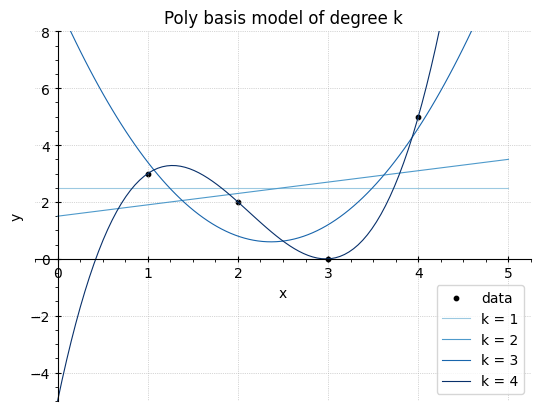

In [24]:
k_values = [1,2,3,4]
lm = fit_lin_reg(xdata, ydata, k_values)
fig, ax = plot_models(xdata, ydata, lm, 0, 5, -5, 8, colormap='Blues')
print("k     w0        w1        w2        w3        MSE")
for k, w, _, mse in lm:
    padded = np.pad(w, (0, 4 - len(w)), 'constant', constant_values=np.nan)
    print(f"{k:<2}  "
          f"{padded[0]:>8.4f}  "
          f"{padded[1]:>8.4f}  "
          f"{padded[2]:>8.4f}  "
          f"{padded[3]:>8.4f}  "
          f"{mse:>12.5g}")

## Question 2

### Load Data

In [25]:
xdata, ydata = gen_data(30)

### Q2.a.i

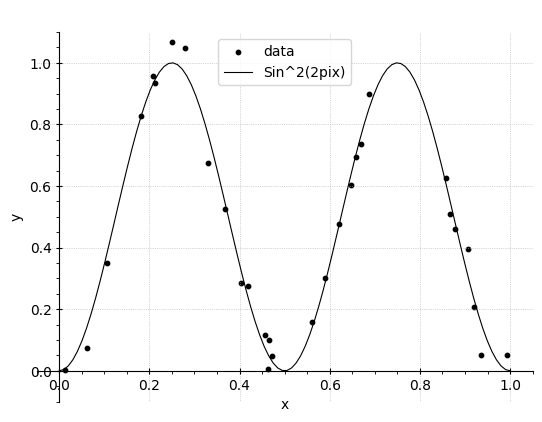

In [26]:
x_points = np.linspace(0,1,100)
fig, ax = plt.subplots()

ax.scatter(xdata, ydata, color='black', label='data', s=10)

ax.plot(x_points,g(x_points), color = 'black' ,label='Sin^2(2pix)', linewidth=0.8)

ax.set_ylim(-0.1, 1.1)

ax.spines['left'].set_position('zero')
ax.spines['bottom'].set_position('zero')
ax.spines['right'].set_color('none')
ax.spines['top'].set_color('none')

ax.xaxis.set_ticks_position('bottom')
ax.yaxis.set_ticks_position('left')
ax.tick_params(axis='both', direction='inout', length=4)

ax.xaxis.set_minor_locator(ticker.AutoMinorLocator(4))
ax.yaxis.set_minor_locator(ticker.AutoMinorLocator(4))
ax.tick_params(which='minor', length=2)

ax.grid(True, linestyle=':', linewidth=0.5)
ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_title(' ')
ax.legend()

### Q2.a.ii

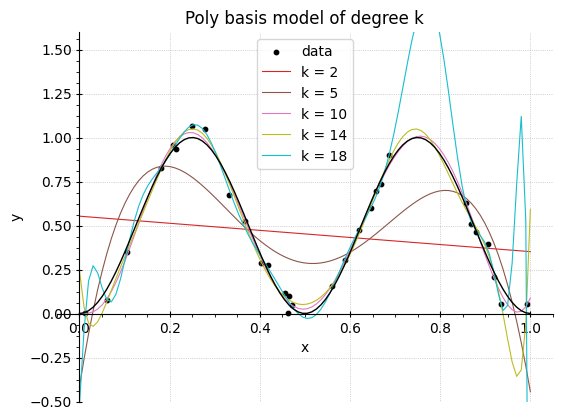

In [27]:
k_values = [2,5,10,14,18]
lm = fit_lin_reg(xdata, ydata, k_values)
fig, ax = plot_models(xdata, ydata, lm, 0, 1, -0.5, 1.6, truFunc = g)


### Q2.b-d Summary table

k | Train N=30,r=1 | Test N=1000,r=1 | Train N=30,r=100 | Test N=1000,r=100
1 | 0.15748812183818103 | 0.13630817190460157 | 0.1263659713672852 | 0.13464804889114773
2 | 0.15739626202839502 | 0.1363280115757867 | 0.12156250189743725 | 0.13954172472152737
3 | 0.13597218734500405 | 0.12472188521284232 | 0.11049491596772898 | 0.14012825504308654
4 | 0.1321780079304026 | 0.1271522744417983 | 0.10530224012049856 | 0.15627382042027596
5 | 0.03306410177138062 | 0.06350190972395868 | 0.03302110384944524 | 0.07032838132246719
6 | 0.03088263684624602 | 0.06488825471876282 | 0.029503104478059837 | 0.13833474203782975
7 | 0.0049002259361994776 | 0.010009686330910494 | 0.005053486937047118 | 0.01779592457996232
8 | 0.004780949346191848 | 0.010643039031445421 | 0.004571157229463628 | 0.07840810356252516
9 | 0.002966304781424182 | 0.01044337378138246 | 0.003372902273802624 | 1.333003530819041
10 | 0.00295951979147314 | 0.011157082766653129 | 0.0032113660926097547 | 0.32105275438623443
11 | 0.002926595

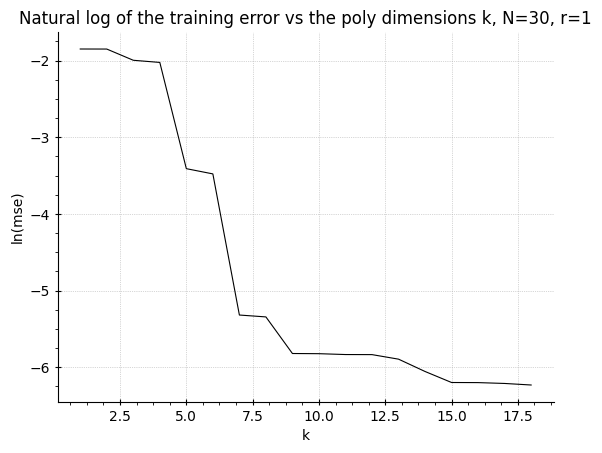

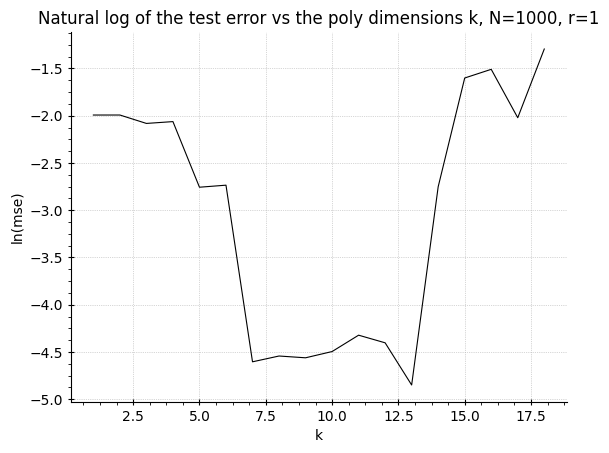

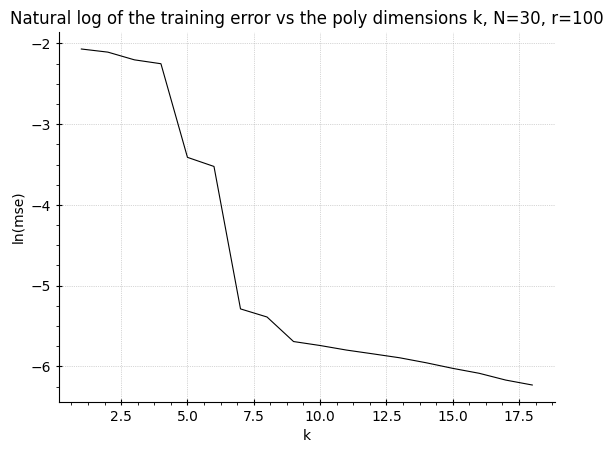

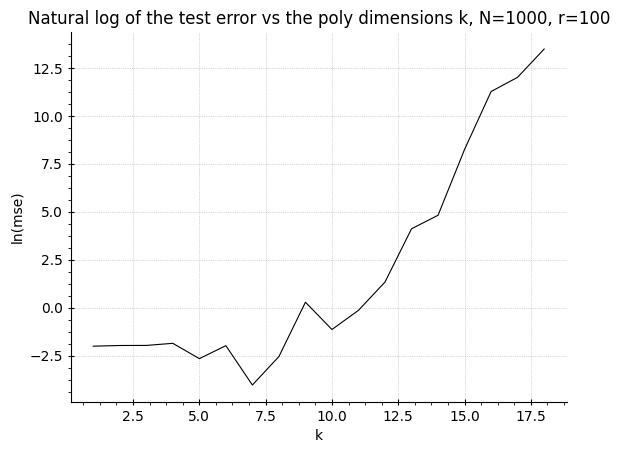

In [28]:
def experiment_Q2_b_d (smallN, largeN, r, k_values, basis_func=poly_basis):
    """
        Q2(b-d) experiments to evaluate model performance
        Fits models on a small training dataset, evalutes test error on a large dataset and averages results over r reps for both training and test mse.

        Arguments:
            smallN (int): training dataset size
            largeN (int): test dataset size
            r (int): number of repetitions
            k_values (list[int]): degrees k
            basis_func (callable, optional): basis function used
        Return:
            list : list of mse results [train N=smallN, test N=largeN, avg train, avg test]
    """
    mse=[]
    #(b) Single run, N = smallN
    xdata, ydata = gen_data(smallN)
    lm = fit_lin_reg(xdata, ydata, k_values, basis_func) #compute w,y_hat, mse train for basis
    df = pd.DataFrame(lm, columns=['k', 'w', 'y_hat', 'mse'])
    mse.append(df['mse'].to_list())
    fig, ax = plot_mse(df['k'], np.log(df['mse']), smallN, 1, basis_func=basis_func)

    #(c) Single run (test error), N = largeN
    xtest, ytest = gen_data(largeN)
    mse_test = []
    for k, w, _, _ in lm: #loop over all k values
        lmtest = lin_reg_sol_k(xtest, ytest, k, basis_func, w=w) #compute y_hat, mse test for basis using weights from training run
        mse_test.append(lmtest[2])
    mse.append(mse_test)
    df = pd.DataFrame({'k': k_values, 'mse': mse_test})
    fig, ax = plot_mse(df['k'], np.log(df['mse']), largeN, 1, basis_func=basis_func, datatype = 'test')

    #(d) Average results over r runs
    df, w = r_sims(smallN, r, k_values, basis_func) #compute avg train mse and w for r runs with basis
    mse.append(df['avg_mse'].to_list())
    fig, ax = plot_mse(df['k'], np.log(df['avg_mse']), smallN, r, basis_func=basis_func)
    df, _ = r_sims(largeN, r, k_values, basis_func, wlist=w) #compute avg test mse for r runs with basis using weights from training run
    mse.append(df['avg_mse'].to_list())
    fig, ax = plot_mse(df['k'], np.log(df['avg_mse']), largeN, r, basis_func=basis_func, datatype = 'test')

    return mse

k_values = [i for i in range(1,19)]
mse = experiment_Q2_b_d(30, 1000, 100, k_values) # does Q2 part b to d with polynomial basis

print("k | Train N=30,r=1 | Test N=1000,r=1 | Train N=30,r=100 | Test N=1000,r=100")
for k, t1, te1, t100, te100 in zip(k_values, mse[0], mse[1], mse[2], mse[3]):
    print(f"{k} | {t1} | {te1} | {t100} | {te100}")


## Question 3

k | Train N=30,r=1 | Test N=1000,r=1 | Train N=30,r=100 | Test N=1000,r=100
1 | 0.14971459309028606 | 0.14351306058285496 | 0.144851831319319 | 0.156662005563031
2 | 0.11337752946753013 | 0.18282230637856942 | 0.13814919143587157 | 0.1647227809031188
3 | 0.02548522551541639 | 0.03333182901304329 | 0.028531560732478877 | 0.03576197291597534
4 | 0.02546360206412841 | 0.033453007105544094 | 0.027260374827171346 | 0.037843382785741626
5 | 0.00360663819973712 | 0.006747077162996377 | 0.004951937355932201 | 0.007341480934656026
6 | 0.0035866426934491255 | 0.006803322959563628 | 0.004770222450645491 | 0.007875908754193318
7 | 0.0029160843449553176 | 0.006092926082601407 | 0.0038377291449971426 | 0.006855692800097381
8 | 0.002872432022552563 | 0.0064029494495514835 | 0.003669499331994825 | 0.007370217933673929
9 | 0.0028602550112788792 | 0.006142176804455945 | 0.00341320505101301 | 0.008109660363069886
10 | 0.0027595796513739065 | 0.005762503637537564 | 0.003249388161921197 | 0.010260119573113

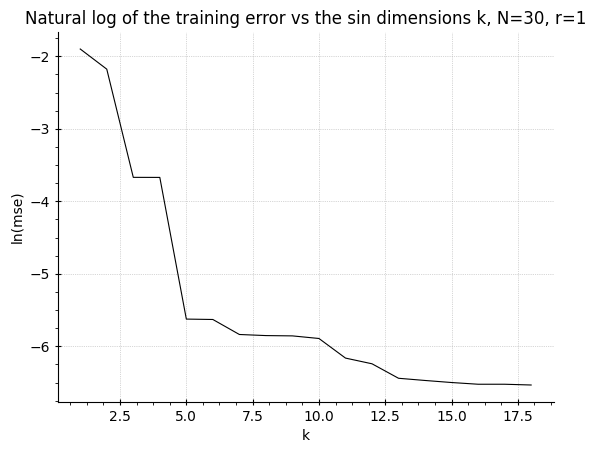

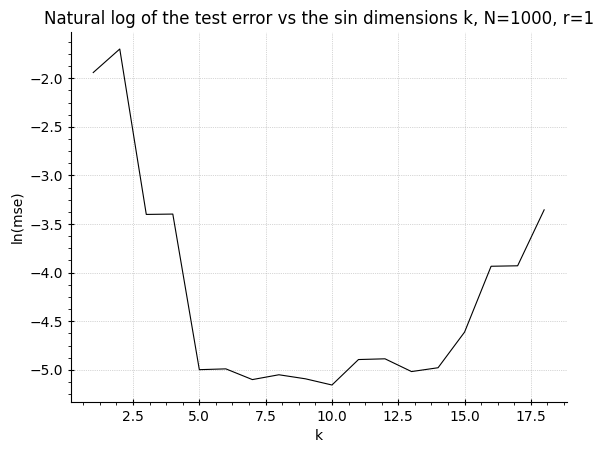

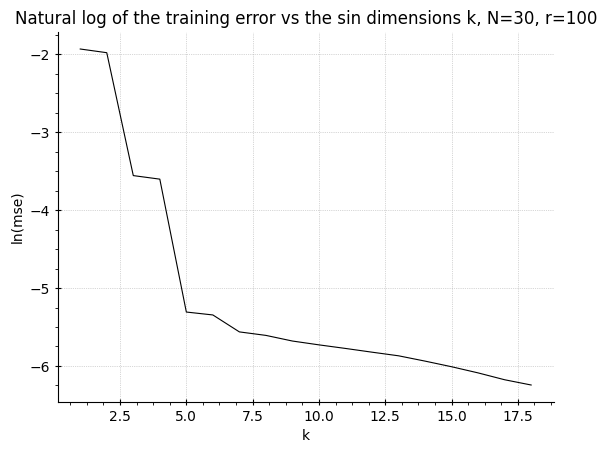

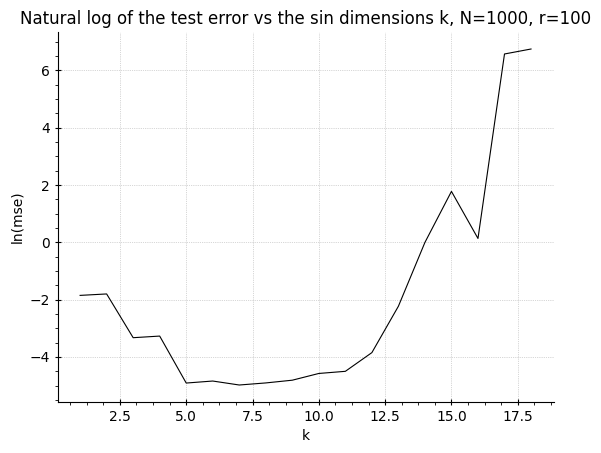

In [29]:
k_values = [i for i in range(1, 19)]
mse = experiment_Q2_b_d(30, 1000, 100, k_values, basis_func=sin_basis) # does Q2 part b to d using sin basis instead

print("k | Train N=30,r=1 | Test N=1000,r=1 | Train N=30,r=100 | Test N=1000,r=100")
for k, t1, te1, t100, te100 in zip(k_values, mse[0], mse[1], mse[2], mse[3]):
    print(f"{k} | {t1} | {te1} | {t100} | {te100}")
plt.show()
plt.close('all')